# HW2P2: Image Recognition and Verification

> This is the second homework assignment for **11-785: Introduction to Deep Learning**, which focuses on the task of **image verification**. In this assignment, we first train a custom **convolutional neural network (CNN)** to perform **face classification** over **8,631 distinct identities**.
>
> Once the model is trained, we use it to extract **face embeddings** for images. These embeddings are then compared across pairs of images to determine whether the two faces belong to the **same identity** or **different identities**, thereby solving the image verification problem.


## 📅 Submission Schedule
- ✅ **Checkpoint:** October 2, 2026 @ 11:59 PM (EST)  
- 🏁 **Final Submission:** October 9, 2026 @ 11:59 PM (EST)  
  *Slack deadline: October 23, 2026 @ 11:59 PM (EST)*  
- 💻 **Code Submission:**
  - Due: October 11, 2026 @ 11:59PM (EST)
  - Closes: October 23, 2026 @ 11:59 PM (EST) *or day-of via Slack*

## Requirement Acknowledgement

Setting the flag below to **True** indicates that you have read, understood, and agree to comply with **all** of the following requirements:

1. **Slack Days Usage**  
   Slack days may be used **only** for the **P2 Final submission**, *not* for the checkpoint.  
   Specifically, slack days may be applied to submit **final P2 Kaggle scores** to the **Slack Kaggle Competition**, at the expense of your available slack days.

2. **Final Code Submission Deadline**  
   The final **Gradescope code submission** is due **within 48 hours after** the Kaggle competition deadline.

3. **Kaggle Username & Score Verification**  
   You must provide your **Kaggle username** below. We will use it to retrieve your official **PRIVATE leaderboard** score.  
   Minor score or output variance is acceptable; however, any discrepancies caused by **modifications to the required submission code**
   (including the notebook’s final submission cell) will result in an **Academic Integrity Violation (AIV)**.

4. **Model Implementation Restrictions**  
   You are **not permitted** to use pre-trained or pre-loaded models (e.g., from Hugging Face or similar libraries).  
   You **may** implement models described in research papers or articles, but they **must** be implemented **from scratch**
   using fundamental PyTorch components (e.g., `Linear`, `Conv2d`, etc.).

5. **Data Usage Restrictions**  
   The use of **any external data or datasets** is strictly prohibited at **any stage** of this assignment.

6. **Collaboration Policy**  
   You may collaborate with teammates to run experiments or ablations.  
   However, you must submit **your own code** and **your own results**.

7. **Academic Integrity**  
   Failure to comply with any of the above requirements will be treated as an **Academic Integrity Violation (AIV)**.

8. **Late Submissions**  
   Late submissions **must** be submitted through the **Slack Kaggle Competition** (see write-up for details).  
   Submissions made to the **regular Kaggle competition** after the original deadline will **not** be considered,
   regardless of remaining slack days.
   
   Gradescope code submission will close at **the same time** as the Slack Kaggle Competition, rather than remaining open for an additional 48 hours.


In [1]:
# @title Click to acknowledge then run cell!
ACKNOWLEDGED = True # @param {"type":"boolean","placeholder":"False"}


## Welcome to the World of Convolutions!

In the previous homework, you explored **Multi-Layer Perceptrons (MLPs)**—the foundational building blocks of deep learning. You saw how MLPs can learn patterns from data, predict phonemes from speech, and even approximate complex functions. However, despite their expressive power, MLPs are not well-suited for image data. Flattening an image into a one-dimensional vector discards crucial **spatial information**, such as how neighboring pixels relate to one another.

This limitation motivates the use of **Convolutional Neural Networks (CNNs)**. CNNs preserve spatial structure by operating directly on image grids, allowing models to learn meaningful visual patterns. In doing so, they bring us closer to designing systems that can truly *see* and interpret the visual world.

In this homework, you will dive into CNNs through **face classification** and **face verification** tasks. In face classification, the goal is to identify a face as belonging to one of several known identities. In contrast, face verification asks a different question: *Do these two images belong to the same person?*—even if that person was never seen during training.

To make this concrete, imagine being given a photo of a friend and a group photo. A classifier would attempt to name your friend, while a verification model would simply determine whether the two images depict the same individual. CNNs enable this by learning **hierarchical features**: early layers capture edges and textures, while deeper layers encode higher-level concepts such as facial structures and distinctive features.

A key theme of this assignment is understanding how **loss functions** shape model behavior. Classification models typically rely on **Cross-Entropy Loss**, which encourages correct label prediction. Verification tasks, however, depend on learning meaningful **embeddings**, where similarity in feature space reflects identity similarity. Loss functions such as **Triplet Loss** or **ArcFace Loss** are designed for this purpose, pulling embeddings of the same person closer together while pushing different identities apart. A well-trained verification model can even distinguish between visually similar individuals—such as siblings—while remaining robust to changes in pose, lighting, or expression.

Beyond theory, this homework emphasizes **practical deep learning skills**. You will preprocess image data, apply data augmentation techniques (e.g., random cropping or flipping), and experiment with modern CNN architectures such as **ResNet** or **ConvNeXt**. Along the way, you will discover that a model optimized for classification is not automatically suitable for verification—highlighting the importance of aligning architectural choices and loss functions with the task at hand.

By the end of this assignment, you will have built a robust face recognition system inspired by real-world applications, from smartphone unlocking to identity verification systems. Let’s get started.

---

## How to run this: three stages

Do not change more than one thing at a time. Each stage has a single question it answers.

**Stage 1 — does the pipeline work? (`head_type='linear'`, `epochs=8`)**
Plain CE + label smoothing on the ResNet-34. You are not chasing a score here, you are
checking that train accuracy climbs, dev accuracy tracks it, and EER falls below ~30%.
Submit this to Kaggle to clear the checkpoint cutoff. Expect roughly 55-70% dev accuracy
and 15-25% EER depending on how long you run it.

**Stage 2 — make the embedding geometry right (`head_type='arcface'`, `epochs=30-40`)**
This is the change that moves verification. CE only asks for `s_y > max_k s_k`; ArcFace
asks for a *margin* in the same angular space the EER is computed in. Classification
accuracy may barely move — EER should drop substantially. That gap is the whole lesson of
section 5.3 in the writeup.

**Stage 3 — ablations, one at a time**
`embedding_head='gdc'` -> `use_se=True` -> longer schedule -> stronger augmentation ->
test-time flip augmentation on the verification embeddings. Log each to W&B with a run
name that says what changed.

A note on Mixup/CutMix: the writeup flags that label mixing interacts badly with
margin-based softmax (the margin is defined for one ground-truth class). Leave them off in
Stage 2. If you want them, use them in a CE-only run and compare honestly.

---

# **SET-UP**


Click [**HERE**](https://www.kaggle.com/t/d025d75eb26d436da206a8e7aaa38235) to join the competition first!

## **Colab Users**
Follow the steps below to set up your Google Colab environment.

### Step 1: Verify GPU
Check that a GPU is available:

In [2]:
!nvidia-smi

Wed Oct  7 13:50:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Step 2: Install Required Packages

In [3]:
!pip install wandb==0.23.1 pytorch_metric_learning torchinfo kaggle==1.8.0 flax --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.9/22.9 MB 78.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.3/256.3 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.8/127.8 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.6/15.6 MB 94.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 43.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 532.0/532.0 kB 22.2 MB/s eta 0:00:00


### Step 3: Configure Kaggle API Access

⚠️ **Important:** You must provide your own Kaggle API credentials for data downloads, while creating your deliverables for code submission and (optionally) submitting to the competition.

#### How to obtain your Kaggle API credentials

1. Navigate to your **Kaggle Profile → Settings** tab.
2. Click **“Genetate New Token”**
3. Copy and paste the access token below


In [4]:
import os
import pprint
os.environ['KAGGLE_USERNAME'] = "koomemartin" # TODO: Verify in Settings
os.environ['KAGGLE_API_TOKEN'] = os.environ.get("KAGGLE_API_TOKEN", "").strip() # TODO: Add Access Token (must be the new token starting with "KGAT_")

# Verify
import kaggle
api = kaggle.api  # Already authenticated on import
api.competitions_list_cli()

ref                                                                           deadline             category         reward  teamCount  userHasEntered  
----------------------------------------------------------------------------  -------------------  --------  -------------  ---------  --------------  
https://www.kaggle.com/competitions/passenger-screening-algorithm-challenge   2017-12-15 23:59:00  Featured  1,500,000 Usd        518           False  
https://www.kaggle.com/competitions/zillow-prize-1                            2018-01-10 15:59:00  Featured  1,200,000 Usd       3770           False  
https://www.kaggle.com/competitions/data-science-bowl-2017                    2017-04-12 23:59:00  Featured  1,000,000 Usd       1972           False  
https://www.kaggle.com/competitions/vesuvius-challenge-ink-detection          2023-06-14 23:59:00  Featured  1,000,000 Usd       1249           False  
https://www.kaggle.com/competitions/arc-prize-2026-arc-agi-3                  2026-11-02

### Step 4: Download Dataset

In [5]:
# api.competition_download_files('hw-2-p-2-fall-2026-student-competition')
# !unzip -qo /content/hw-2-p-2-fall-2026-student-competition.zip -d /content
# !rm -rf /content/hw-2-p-2-fall-2026-student-competition.zip

In [6]:
# !du -h --max-depth=2 /content/hw2p2_data

## **Kaggle Users**



### Step 1: Environment Setup

In [7]:
!pip install wandb==0.23.1 pytorch_metric_learning torchinfo kaggle==1.8.0 flax --quiet

### Step 2: Get Data

If you are using Kaggle, follow these steps to add the dataset directly to your notebook:
1. Join the kaggle competition (https://www.kaggle.com/t/d025d75eb26d436da206a8e7aaa38235)
2. Open your **Kaggle Notebook**.  
3. Navigate to **Notebook → Input**.  
4. Click **Add Input**.  
5. Choose "Competition Datasets" and "Your work", and then you'll be able to see the competiation "hw-2-p-2-fall-2026-student-competition"
6. Click the **➕ (plus sign)** to add the dataset to your notebook.  

### Step 3: Configure Kaggle API Access

⚠️ **Important:** You must provide your own Kaggle API credentials while creating your deliverables for code submission and (optionally) submitting to the competition.

#### How to obtain your Kaggle API credentials

1. Navigate to your **Kaggle Profile → Settings** tab.
2. Click **“Genetate New Token”**
3. Copy and paste the access token below


In [8]:
import os
import pprint
os.environ['KAGGLE_USERNAME'] = "koomemartin" # TODO: Verify in Settings
os.environ['KAGGLE_API_TOKEN'] = os.environ.get("KAGGLE_API_TOKEN", "").strip() # TODO: Add Access Token (must be the new token starting with "KGAT_")

# Verify
import kaggle
api = kaggle.api  # Already authenticated on import
api.competitions_list_cli()

ref                                                                           deadline             category         reward  teamCount  userHasEntered  
----------------------------------------------------------------------------  -------------------  --------  -------------  ---------  --------------  
https://www.kaggle.com/competitions/passenger-screening-algorithm-challenge   2017-12-15 23:59:00  Featured  1,500,000 Usd        518           False  
https://www.kaggle.com/competitions/zillow-prize-1                            2018-01-10 15:59:00  Featured  1,200,000 Usd       3770           False  
https://www.kaggle.com/competitions/data-science-bowl-2017                    2017-04-12 23:59:00  Featured  1,000,000 Usd       1972           False  
https://www.kaggle.com/competitions/vesuvius-challenge-ink-detection          2023-06-14 23:59:00  Featured  1,000,000 Usd       1249           False  
https://www.kaggle.com/competitions/arc-prize-2026-arc-agi-3                  2026-11-02

## **PSC Users**

### Step 1: Setting Up Your Environment on Bridges2

❗️⚠️ For this homework, we are **providing a shared Conda environment** for the entire class. Therefore, PSC users **do not need to manually install any packages**.

❗️⚠️ For this homework, you need to **download the dataset to the node `$LOCAL`** to avoid I/O bottlenecks from the shared filesystem. This means that each time you run on a new node, you need to download the dataset again. However, as long as you stay on the same node, you do not need to re-download the dataset. Please refer to **Step 3** for the detailed procedure.

Follow these steps to set up the environment and start a Jupyter notebook on Bridges2:

- To run your notebook more efficiently on PSC, we need to use a **Jupyter Server** hosted on a compute node.

- You can use your prefered way of connecting to the Jupyter Server.  **The recommended way is to connect in VSCode.**
Follow the instructions below.



#### **Connect in VSCode**
SSH into Bridges2 and navigate to your **Jet directory** (`Jet/home/<your_psc_username>`). Upload your notebook there, and then connect to the Jupyter Server from that directory.

#### **1.1 SSH into Bridges2**
1）Open VS Code and click on the `Extensions` icon in the left sidebar. Make sure the "**Remote - SSH**" extension is installed.

2）Open the command palette (**Shift+Command+P** on Mac, **Ctrl+Shift+P** on Windows). A search box will appear at the top center. Choose `"Remote-SSH: Add New SSH Host"`, then enter:

```bash
ssh <your_username>@bridges2.psc.edu #change <your_username> to your username
```

Next, choose `"/Users/<your_username>/.ssh/config"` as the config file. A dialog will appear in the bottom right saying "Host Added". Click `"Connect"`, and then enter your password.

(Note: After adding the host once, you can later use `"Remote-SSH: Connect to Host"` and select "bridges2.psc.edu" from the list.)

3）Once connected, click `"Explorer"` in the left sidebar > "Open Folder", and navigate to your home directory under the project grant:
```bash
/jet/home/<your_username>  #change <your_username> to your username
```

4）You can now drag your notebook files directly into the right-hand pane (your remote home directory), or upload them using `scp` into your folder.

> ❗️⚠️ The following steps should be executed in the **VSCode integrated terminal**.

#### **1.2 Navigate to Your Directory**
Make sure to use this `/jet/home/<your_username>` as your working directory, since all subsequent operations (up to submission) are based on this path.
```bash
cd /jet/home/<your_username>  #change <your_username> to your username
```

#### **1.3 Request a Compute Node**
```bash
interact -p GPU-shared --gres=gpu:v100-32:1 -t 8:00:00 -A cis250019p
```

#### **1.4 Load the Anaconda Module**
```bash
module load anaconda3
```

#### **1.5 Activate the provided HW Environment**
```bash
conda deactivate # First, deactivate any existing Conda environment
conda activate /ocean/projects/cis250019p/mzhang23/TA/envs/IDLF26 && export PYTHONNOUSERSITE=1
```

#### **1.6 Start Jupyter Notebook**
Launch Jupyter Notebook:
```bash
jupyter notebook --no-browser --ip=0.0.0.0
```

Go to **Kernel** → **Select Another Kernel** → **Existing Jupyter Server**
   Enter the URL of the Jupyter Server:```http://{hostname}:{port}/tree?token={token}```
   
   *(Usually, this URL appears in the terminal output after you run `jupyter notebook --no-browser --ip=0.0.0.0`, in a line like:  “Jupyter Server is running at: http://...”)*

   - eg: `http://v011.ib.bridges2.psc.edu:8888/tree?token=e4b302434e68990f28bc2b4ae8d216eb87eecb7090526249`

> **Note**: Replace `{hostname}`, `{port}` and `{token}` with your actual values from the Jupyter output.

After launching the Jupyter notebook, you can run the cells directly inside the notebook — no need to use the terminal for the remaining steps.

#### **1.7 Navigate to Your Jet Directory**

After launching the Jupyter notebook, you can run the cells directly inside the notebook — no need to use the terminal for the remaining steps.

First, navigate to your **Jet directory** (`/jet/home/<your_username>`).

️❗️⚠ Please make sure to use your **Jet directory**, not the **Ocean path** — **all HW setup and outputs below are based on this directory**.

In [9]:
# # Make sure you are in your directory
# !pwd #should be /jet/home/<your_username>, if not, uncomment the following line and replace with your actual username:
# %cd /jet/home/<your_username>
# #TODO: replace the "<your_username>" to yours

### Step 2: Configure Kaggle API Access

⚠️ **Important:** You must provide your own Kaggle API credentials for data downloads, while creating your deliverables for code submission and (optionally) submitting to the competition.

#### How to obtain your Kaggle API credentials

1. Navigate to your **Kaggle Profile → Settings** tab.
2. Click **“Genetate New Token”**
3. Copy and paste the access token below


In [10]:
# import os
# import pprint
# os.environ['KAGGLE_USERNAME'] = "<your-username>" # TODO: Verify in Settings
# os.environ['KAGGLE_API_TOKEN'] = "<your-key>" # TODO: Add Access Token (must be the new token starting with "KGAT_")

# # Verify
# import kaggle
# api = kaggle.api  # Already authenticated on import
# api.competitions_list_cli()

### Step 3: Get Data

❗️⚠️ In this homework, you need to download the dataset to the **GPU node’s local storage (`$LOCAL`)** instead of using the shared /ocean directory, in order to avoid I/O bottlenecks. Using the shared filesystem may slow down training drastically and can take hours per epoch.

Note that **the local storage on a compute node is temporary and will be cleared** when your node time limit is reached or when you move to a different node. Therefore, **every time you run on a new node, you need to re-run the dataset download step**. However, as long as you stay on the same node, you do NOT need to download the dataset again.

Join the HW2P2 kaggle competition (https://www.kaggle.com/t/d025d75eb26d436da206a8e7aaa38235)

In [11]:
# api.competition_download_files('hw-2-p-2-fall-2026-student-competition', path=os.environ["LOCAL"])
# !unzip -qo $LOCAL/hw-2-p-2-fall-2026-student-competition.zip -d $LOCAL
# !rm -f $LOCAL/hw-2-p-2-fall-2026-student-competition.zip

You can run the following block to explore the shared directory structure:

(Note: You do **NOT** need to change any `data_path` in the code below. Each time you start on a new node, as long as you run the dataset download block above, your dataset will always be located at:`/local/hw2p2_data`. This path will not change even if you are assigned to a different node.)

In [12]:
# import os
# data_path = "/local/hw2p2_data" # this is the path of the dataset on your node
# print("Files in shared hw2p2 dataset:", os.listdir(data_path))

In [13]:
# !tree -L 2 /local/hw2p2_data | head -n 20

# Imports

In [14]:
import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import torch.nn.functional as F
import torch.nn as nn
import torch.optim as optim
from torchsummary import summary
import torchvision
from torchvision.io import decode_image
from torchvision.utils import make_grid
from torchvision import transforms
import torchvision.transforms.v2 as T
import os
import gc
from tqdm import tqdm
from tqdm.auto import tqdm
from PIL import Image
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn import metrics as mt
from scipy.optimize import brentq
from scipy.interpolate import interp1d
import glob
import wandb
import matplotlib.pyplot as plt
from pytorch_metric_learning import samplers
import csv
import pandas as pd

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device: ", DEVICE)


Device:  cuda


# Config

### ⚠️ `Note`

- You will need to set the root path to your `hw2p2_data` folder in `data: root:`. This will depend on your setup. For eg. if you are following out setup instruction:
  - `Colab`: `"/content/hw2p2_data"`
  - `Kaggle`: `"/kaggle/input/competitions/hw-2-p-2-fall-2026-student-competition/hw2p2_data"`
  - `PSC`: `"/local/hw2p2_data"`

Kindly modify your configurations to suit your ablations and be keen to include your name.

In [15]:
import random
import pprint

config = {
    # ----------------------------- paths -----------------------------
    # Colab : "/content/hw2p2_data"
    # Kaggle: "/kaggle/input/competitions/hw-2-p-2-fall-2026-student-competition/hw2p2_data"
    # PSC   : "/local/hw2p2_data"
    'data_root':      "/kaggle/input/competitions/hw-2-p-2-fall-2026-student-competition/hw2p2_data",                  # TODO: set for your platform
    'checkpoint_dir': "/kaggle/working/checkpoints/resnet34_baseline",

    # ----------------------------- data ------------------------------
    'image_size':   112,
    'batch_size':   256,      # 256 fits a V100-32GB with AMP; drop to 128/64 on a T4
    'num_workers':  8,        # PSC: 8, Colab/Kaggle: 2-4
    'num_classes':  8631,
    'augment':      True,

    # ----------------------------- model -----------------------------
    'arch':           'resnet34',   # 'resnet18' | 'resnet34' | 'resnet50'
    'embedding_head': 'gdc',        # 'gap' (baseline) | 'gdc' | 'flatten'  -> see ablation notes
    'embedding_dim':  512,
    'dropout':        0.3,

    # STAGE 1 -> 'linear'  (plain CE, sanity check + checkpoint submission)
    # STAGE 2 -> 'arcface' (margin softmax, this is what moves verification EER)
    'head_type':      'linear',

    # ----------------------------- loss ------------------------------
    'label_smoothing':      0.1,
    'arcface_scale':        64.0,
    'arcface_margin':       0.5,
    'margin_warmup_epochs': 3,      # ramp m: 0 -> arcface_margin, stabilises early training

    # ---------------------------- optim ------------------------------
    'lr':            0.1,     # linear-scaling rule: 0.1 * (batch_size / 256)
    'momentum':      0.9,
    'weight_decay':  5e-4,
    'nesterov':      True,
    'epochs':        15,      # 8-10 is enough for the checkpoint cutoff; 40-60 for the high cutoff
    'warmup_epochs': 2,
    'min_lr':        1e-5,
    'grad_clip':     3.0,

    # ----------------------------- misc ------------------------------
    'seed': 11785,
}

# the starter cells below use the (mis-spelled) key 'augument' -- keep both in sync
config['augument'] = config['augment']

# lr is defined for batch_size=256; rescale automatically if you change the batch size
config['lr'] = config['lr'] * (config['batch_size'] / 256)


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True   # fixed input size -> let cuDNN autotune

set_seed(config['seed'])
pprint.pprint(config)

{'arcface_margin': 0.5,
 'arcface_scale': 64.0,
 'arch': 'resnet34',
 'augment': True,
 'augument': True,
 'batch_size': 256,
 'checkpoint_dir': '/kaggle/working/checkpoints/resnet34_baseline',
 'data_root': '/kaggle/input/competitions/hw-2-p-2-fall-2026-student-competition/hw2p2_data',
 'dropout': 0.3,
 'embedding_dim': 512,
 'embedding_head': 'gdc',
 'epochs': 15,
 'grad_clip': 3.0,
 'head_type': 'linear',
 'image_size': 112,
 'label_smoothing': 0.1,
 'lr': 0.1,
 'margin_warmup_epochs': 3,
 'min_lr': 1e-05,
 'momentum': 0.9,
 'nesterov': True,
 'num_classes': 8631,
 'num_workers': 8,
 'seed': 11785,
 'warmup_epochs': 2,
 'weight_decay': 0.0005}


# Data Augumentations

In [16]:
def create_transforms(image_size: int = 112, augment: bool = True) -> T.Compose:
    """
    Transform pipeline for face recognition.

    Note: ImageDataset yields a float tensor in [0, 1] (decode_image / 255.0), so we start
    from ToImage()/ToDtype() rather than ToTensor() (deprecated in transforms.v2).

    Augmentation choices, and why:
      - RandomHorizontalFlip : a mirrored face is the same identity -> free 2x data. Always on.
      - RandomResizedCrop    : simulates detector jitter / scale variation between the
                               classification crops and the verification crops.
      - ColorJitter          : lighting and camera white-balance vary a lot in VGGFace2.
      - RandomGrayscale      : stops the model leaning on skin/hair colour as an identity cue
                               (colour is exactly the shortcut that breaks on unseen identities).
      - RandomErasing        : cheap occlusion proxy (glasses, hands, hair, crops).
      - NO vertical flip, NO large rotation: upside-down faces do not occur at test time.
    """
    # Step 1: always-on, convert to a float32 tensor image
    transform_list = [
        T.ToImage(),
        T.ToDtype(torch.float32, scale=True),
    ]

    # Step 2: augmentation (train only)
    if augment:
        transform_list.extend([
            T.RandomResizedCrop(
                image_size, scale=(0.75, 1.0), ratio=(0.9, 1.1), antialias=True
            ),
            T.RandomHorizontalFlip(p=0.5),
            T.RandomApply([T.ColorJitter(brightness=0.3, contrast=0.3,
                                         saturation=0.3, hue=0.05)], p=0.5),
            T.RandomGrayscale(p=0.05),
            T.RandomApply([T.RandomRotation(degrees=10)], p=0.3),
        ])
    else:
        transform_list.append(T.Resize((image_size, image_size), antialias=True))

    # Step 3: normalization -> pixels in [-1, 1]
    transform_list.append(T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]))

    # Step 4: RandomErasing operates on the normalized tensor, so it goes last
    if augment:
        transform_list.append(
            T.RandomErasing(p=0.25, scale=(0.02, 0.15), ratio=(0.3, 3.3), value=0.0)
        )

    return T.Compose(transform_list)

In [17]:
train_transforms = create_transforms(config['image_size'], augment=config['augment'])
val_transforms   = create_transforms(config['image_size'], augment=False)

print("Train pipeline:"); print(train_transforms)
print("Val/Test pipeline:"); print(val_transforms)

Train pipeline:
Compose(
      ToImage()
      ToDtype(scale=True)
      RandomResizedCrop(size=(112, 112), scale=(0.75, 1.0), ratio=(0.9, 1.1), interpolation=InterpolationMode.BILINEAR, antialias=True)
      RandomHorizontalFlip(p=0.5)
      RandomApply(    ColorJitter(brightness=(0.7, 1.3), contrast=(0.7, 1.3), saturation=(0.7, 1.3), hue=(-0.05, 0.05)))
      RandomGrayscale(p=0.05)
      RandomApply(    RandomRotation(degrees=[-10.0, 10.0], interpolation=InterpolationMode.NEAREST, expand=False, fill=0))
      Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5], inplace=False)
      RandomErasing(p=0.25, scale=(0.02, 0.15), ratio=(0.3, 3.3), value=[0.0], inplace=False)
)
Val/Test pipeline:
Compose(
      ToImage()
      ToDtype(scale=True)
      Resize(size=[112, 112], interpolation=InterpolationMode.BILINEAR, antialias=True)
      Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5], inplace=False)
)


# Datasets and DataLoaders

## Classification Datasets and Dataloaders

In [18]:
class ImageDataset(Dataset):
    """Custom dataset for loading images with optional labels."""

    def __init__(self, root, transform, num_classes=None, preload=False):
        """
        Args:
            root (str): Dataset root directory.
                Expected structure:
                  - labeled:
                        root/
                          images/
                          labels.txt   (img label)
                  - unlabeled:
                        root/
                          images/
            transform (callable): Transform applied to images.
            num_classes (int, optional): Number of classes to keep (labeled only).
            preload (bool): Preload images into memory.
        """
        self.root = root
        self.transform = transform
        self.preload = preload

        self.image_paths = []
        self.labels = None      # None → unlabeled dataset
        self.classes = None
        self.images = []

        labels_file = os.path.join(self.root, "labels.txt")
        images_dir = os.path.join(self.root, "images")

        # --------------------------------------------------
        # Detect labeled vs unlabeled dataset
        # --------------------------------------------------
        has_labels = os.path.exists(labels_file)

        if has_labels:
            self.labels = []
            self.classes = set()

            with open(labels_file, "r") as f:
                lines = f.readlines()

            # Sort by label (keeps your original behavior)
            lines = sorted(lines, key=lambda x: int(x.strip().split(" ")[-1]))

            all_labels = sorted(set(int(line.strip().split(" ")[1]) for line in lines))

            if num_classes is not None:
                selected_classes = set(all_labels[:num_classes])
            else:
                selected_classes = set(all_labels)

            for line in tqdm(lines, desc="Loading labeled dataset"):
                img_path, label = line.strip().split(" ")
                label = int(label)

                if label in selected_classes:
                    self.image_paths.append(os.path.join(images_dir, img_path))
                    self.labels.append(label)
                    self.classes.add(label)

            self.classes = sorted(self.classes)

            assert len(self.image_paths) == len(self.labels), "Images and labels mismatch!"

        else:
            # --------------------------------------------------
            # Unlabeled dataset: load all images from images/
            # --------------------------------------------------
            image_files = sorted(os.listdir(images_dir))

            for img in tqdm(image_files, desc="Loading unlabeled dataset"):
                self.image_paths.append(os.path.join(images_dir, img))

        # --------------------------------------------------
        # Preload images if requested
        # --------------------------------------------------
        if self.preload:
            self.images = [
                decode_image(p, mode="RGB") / 255.0
                for p in tqdm(self.image_paths, desc="Preloading images")
            ]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        if self.preload:
            image = self.images[idx]
        else:
            image = decode_image(self.image_paths[idx], mode="RGB") / 255.0

        image = self.transform(image)

        # Return with or without label
        if self.labels is not None:
            return image, self.labels[idx]
        else:
            return image


In [19]:
gc.collect()
cls_data_dir = config['data_root'] + '/cls_data'
print("cls_data contents:", sorted(os.listdir(cls_data_dir)))

# Datasets
#   train -> labeled (root/images + root/labels.txt)
#   dev   -> labeled, used for closed-set validation accuracy
#   test  -> unlabeled, used only for the Kaggle classification submission
cls_train_dataset = ImageDataset(
    root=os.path.join(cls_data_dir, "train"),
    transform=train_transforms,
    num_classes=config['num_classes'],
)
cls_val_dataset = ImageDataset(
    root=os.path.join(cls_data_dir, "dev"),
    transform=val_transforms,            # NEVER augment validation data
    num_classes=config['num_classes'],
)
cls_test_dataset = ImageDataset(
    root=os.path.join(cls_data_dir, "test"),
    transform=val_transforms,
)

assert cls_train_dataset.classes == cls_val_dataset.classes, "Class mismatch!"

# Dataloaders
loader_kwargs = dict(
    num_workers=config['num_workers'],
    pin_memory=True,
    persistent_workers=config['num_workers'] > 0,
)
if config['num_workers'] > 0:
    loader_kwargs['prefetch_factor'] = 4

cls_train_loader = DataLoader(
    cls_train_dataset,
    batch_size=config['batch_size'],
    shuffle=True,
    drop_last=True,          # keeps BatchNorm statistics stable on the last batch
    **loader_kwargs,
)
cls_val_loader = DataLoader(
    cls_val_dataset,
    batch_size=config['batch_size'],
    shuffle=False,
    drop_last=False,
    **loader_kwargs,
)
cls_test_loader = DataLoader(
    cls_test_dataset,
    batch_size=config['batch_size'],
    shuffle=False,
    drop_last=False,
    **loader_kwargs,
)

print(f"train images: {len(cls_train_dataset):,} | dev images: {len(cls_val_dataset):,} "
      f"| test images: {len(cls_test_dataset):,} | classes: {len(cls_train_dataset.classes)}")

cls_data contents: ['dev', 'test', 'train']


Loading labeled dataset:   0%|          | 0/431550 [00:00<?, ?it/s]

Loading labeled dataset:   0%|          | 0/43097 [00:00<?, ?it/s]

Loading unlabeled dataset:   0%|          | 0/43097 [00:00<?, ?it/s]

train images: 431,550 | dev images: 43,097 | test images: 43,097 | classes: 8631


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


## Verification Dataset and Datatloaders

In [20]:
class ImagePairDataset(Dataset):
    """Custom dataset for loading and transforming image pairs (labeled or unlabeled)."""

    def __init__(self, root, pairs_file, transform, preload=False):
        """
        Args:
            root (str): Path to the directory containing the images.
            pairs_file (str): File with:
                - img1 img2 label   (labeled)
                - img1 img2         (unlabeled)
            transform (callable): Transform to apply to images.
            preload (bool): Whether to preload images into memory.
        """
        self.root = root
        self.transform = transform
        self.preload = preload

        self.image1_paths = []
        self.image2_paths = []
        self.matches = None  # None → unlabeled dataset

        # Read file
        with open(pairs_file, "r") as f:
            lines = f.readlines()

        # Detect whether labels exist
        first_cols = lines[0].strip().split()
        has_labels = len(first_cols) == 3

        if has_labels:
            self.matches = []

        for line in tqdm(lines, desc="Loading dataset"):
            parts = line.strip().split()

            if has_labels:
                img1, img2, match = parts
                self.matches.append(int(match))
            else:
                img1, img2 = parts

            self.image1_paths.append(os.path.join(self.root, img1))
            self.image2_paths.append(os.path.join(self.root, img2))

        assert len(self.image1_paths) == len(self.image2_paths)
        if has_labels:
            assert len(self.matches) == len(self.image1_paths)

        # Preload images if requested
        if self.preload:
            self.image1_cache = [
                decode_image(p, mode="RGB") / 255.0
                for p in tqdm(self.image1_paths, desc="Preloading image1")
            ]
            self.image2_cache = [
                decode_image(p, mode="RGB") / 255.0
                for p in tqdm(self.image2_paths, desc="Preloading image2")
            ]

    def __len__(self):
        return len(self.image1_paths)

    def __getitem__(self, idx):
        # Load images
        if self.preload:
            img1 = self.image1_cache[idx]
            img2 = self.image2_cache[idx]
        else:
            img1 = decode_image(self.image1_paths[idx], mode="RGB") / 255.0
            img2 = decode_image(self.image2_paths[idx], mode="RGB") / 255.0

        img1 = self.transform(img1)
        img2 = self.transform(img2)

        # Return with or without label
        if self.matches is not None:
            return img1, img2, self.matches[idx]
        else:
            return img1, img2


In [21]:
gc.collect()
ver_data_dir = config['data_root'] + '/ver_data'
print("ver_data contents:", sorted(os.listdir(ver_data_dir))[:10], "...")


def find_pairs_file(root: str, keyword: str) -> str:
    """The pair list is a .txt whose name contains 'val_pair' / 'test_pair'."""
    cands = [p for p in glob.glob(os.path.join(root, f"*{keyword}*")) if os.path.isfile(p)]
    assert cands, f"No file matching *{keyword}* in {root}. Found: {os.listdir(root)[:20]}"
    return sorted(cands)[0]


val_pairs_file  = find_pairs_file(config['data_root'], "val_pair")
test_pairs_file = find_pairs_file(config['data_root'], "test_pair")
print("val pairs :", val_pairs_file)
print("test pairs:", test_pairs_file)

# The paths inside the pair files may be relative to ver_data/ or to ver_data/images/.
# Resolve it once instead of guessing.
with open(val_pairs_file) as f:
    first_img = f.readline().split()[0]
image_root = ver_data_dir
if not os.path.exists(os.path.join(image_root, first_img)):
    image_root = os.path.join(ver_data_dir, "images")
assert os.path.exists(os.path.join(image_root, first_img)), \
    f"Could not resolve image root for entry '{first_img}'"
print("verification image root:", image_root)

# Datasets  (val pairs are labeled -> used for EER; test pairs are unlabeled -> Kaggle)
ver_val_dataset = ImagePairDataset(
    root=image_root, pairs_file=val_pairs_file, transform=val_transforms
)
ver_test_dataset = ImagePairDataset(
    root=image_root, pairs_file=test_pairs_file, transform=val_transforms
)

# Dataloader (batch_size // 2 because each item is a *pair* -> 2 forward images)
ver_val_loader = DataLoader(
    ver_val_dataset,
    batch_size=max(config['batch_size'] // 2, 32),
    shuffle=False,
    drop_last=False,
    **loader_kwargs,
)
ver_test_loader = DataLoader(
    ver_test_dataset,
    batch_size=max(config['batch_size'] // 2, 32),
    shuffle=False,
    drop_last=False,
    **loader_kwargs,
)

print(f"val pairs: {len(ver_val_dataset):,} | test pairs: {len(ver_test_dataset):,}")

ver_data contents: ['005DnBCJ.jpg', '00ogqjIH.jpg', '00pTd1LL.jpg', '00uA3rkT.jpg', '01KH7cQa.jpg', '01nMCEYR.jpg', '03h9MqyM.jpg', '03sCtQd8.jpg', '03sEX4qL.jpg', '04HnG3HS.jpg'] ...
val pairs : /kaggle/input/competitions/hw-2-p-2-fall-2026-student-competition/hw2p2_data/val_pairs.txt
test pairs: /kaggle/input/competitions/hw-2-p-2-fall-2026-student-competition/hw2p2_data/test_pairs.txt
verification image root: /kaggle/input/competitions/hw-2-p-2-fall-2026-student-competition/hw2p2_data/ver_data


Loading dataset:   0%|          | 0/1000 [00:00<?, ?it/s]

Loading dataset:   0%|          | 0/5000 [00:00<?, ?it/s]

val pairs: 1,000 | test pairs: 5,000


# EDA and Viz

In [22]:
# Double-check your dataset/dataloaders work as expected

print("Number of classes    : ", len(cls_train_dataset.classes))
print("No. of train images  : ", cls_train_dataset.__len__())
print("Shape of image       : ", cls_train_dataset[0][0].shape)
print("Batch size           : ", config['batch_size'])
print("Train batches        : ", cls_train_loader.__len__())
print("Val batches          : ", cls_val_loader.__len__())

# Feel free to print more things if needed

Number of classes    :  8631
No. of train images  :  431550
Shape of image       :  torch.Size([3, 112, 112])
Batch size           :  256
Train batches        :  1685
Val batches          :  169


### Classification Dataset Viz

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


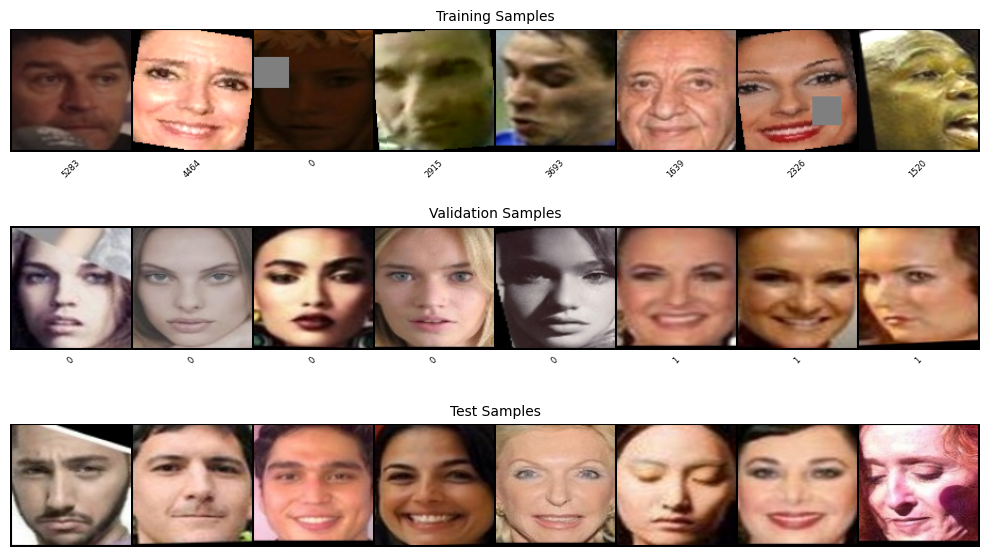

In [23]:
def show_cls_dataset_samples(train_loader, val_loader, test_loader, samples_per_set=8, figsize=(10, 6)):
    """
    Display samples from train, validation, and test datasets side by side

    Args:
        train_loader: Training data loader
        val_loader: Validation data loader
        test_loader: Test data loader
        samples_per_set: Number of samples to show from each dataset
        figsize: Figure size (width, height)
    """
    def denormalize(x):
        """Denormalize images from [-1, 1] to [0, 1]"""
        return x * 0.5 + 0.5

    def get_samples(loader, n, labeled=True):
        """Get n samples from a dataloader"""
        batch = next(iter(loader))

        if labeled:
            return batch[0][:n], batch[1][:n]
        else:
            return batch[:n], None

    # Get samples from each dataset
    train_imgs, train_labels = get_samples(train_loader, samples_per_set, labeled=True)
    val_imgs, val_labels = get_samples(val_loader, samples_per_set, labeled=True)
    test_imgs, test_labels = get_samples(test_loader, samples_per_set, labeled=False)

    # Create figure
    fig, axes = plt.subplots(3, 1, figsize=figsize)

    # Plot each dataset
    for idx, (imgs, labels, title) in enumerate([
        (train_imgs, train_labels, 'Training Samples'),
        (val_imgs, val_labels, 'Validation Samples'),
        (test_imgs, test_labels, 'Test Samples')
    ]):

        # Create grid of images
        grid = make_grid(denormalize(imgs), nrow=8, padding=2)

        # Display grid
        axes[idx].imshow(grid.permute(1, 2, 0).cpu())
        axes[idx].axis('off')
        axes[idx].set_title(title, fontsize=10)

        # Add class labels below images (with smaller font)
        grid_width = grid.shape[2]
        imgs_per_row = min(8, samples_per_set)
        img_width = grid_width // imgs_per_row

        if labels is not None:
            for i, label in enumerate(labels):
                col = i % imgs_per_row

                if label < len(train_loader.dataset.classes):
                    class_name = train_loader.dataset.classes[label]
                else:
                    class_name = f"Class {label} (Unknown)"

                axes[idx].text(
                    col * img_width + img_width/2,
                    grid.shape[1] + 5,
                    class_name,
                    ha='center',
                    va='top',
                    fontsize=6,
                    rotation=45
                )

    plt.tight_layout()
    plt.show()

show_cls_dataset_samples(cls_train_loader, cls_val_loader, cls_test_loader)

### Ver Dataset Viz

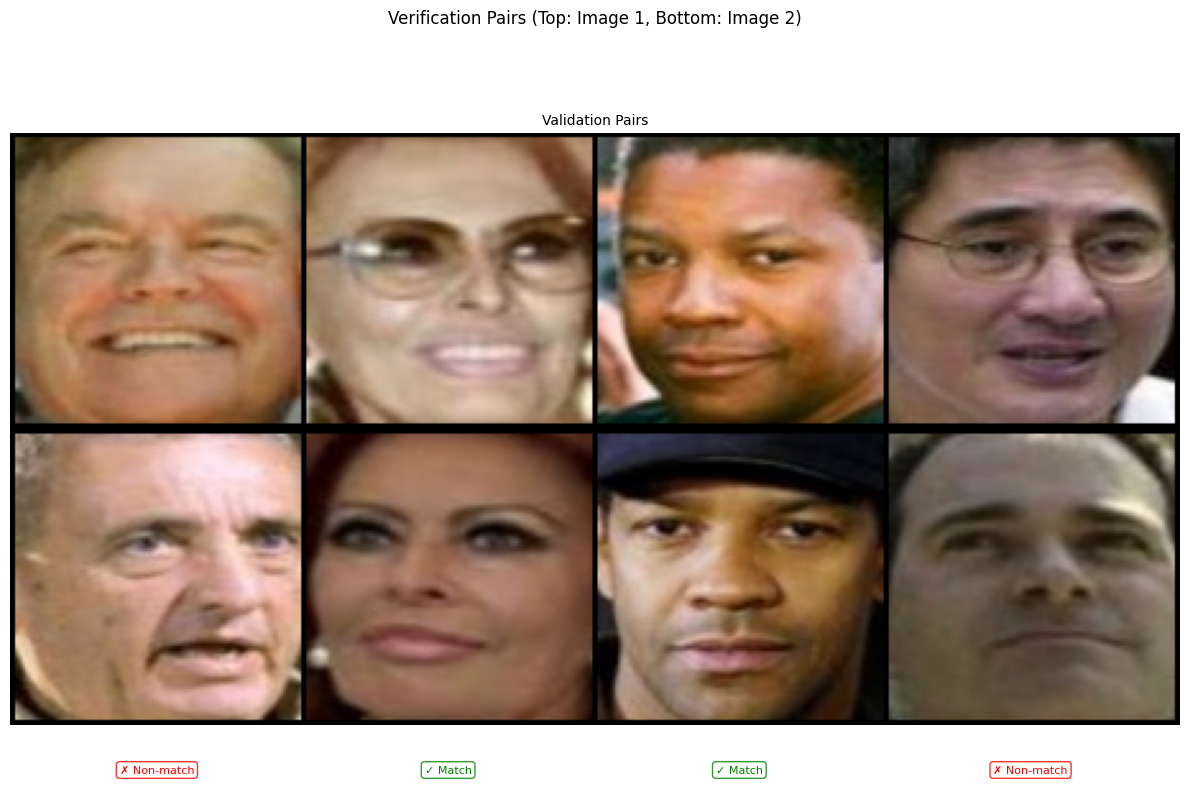

In [24]:
import matplotlib.pyplot as plt
import torch
from torchvision.utils import make_grid

def show_ver_dataset_samples(val_loader, samples_per_set=4, figsize=(12, 8)):
    """
    Display verification pairs from the validation dataset

    Args:
        val_loader: Validation data loader
        samples_per_set: Number of pairs to show from the dataset
        figsize: Figure size (width, height)
    """
    def denormalize(x):
        """Denormalize images from [-1, 1] to [0, 1]"""
        return x * 0.5 + 0.5

    def get_samples(loader, n):
        """Get n samples from a dataloader"""
        batch = next(iter(loader))
        return batch[0][:n], batch[1][:n], batch[2][:n]

    # Get samples from the validation dataset
    val_imgs1, val_imgs2, val_labels = get_samples(val_loader, samples_per_set)

    # Create figure and axis
    fig, ax = plt.subplots(1, 1, figsize=figsize)

    # Create grids for both images in each pair
    grid1 = make_grid(denormalize(val_imgs1), nrow=samples_per_set, padding=2)
    grid2 = make_grid(denormalize(val_imgs2), nrow=samples_per_set, padding=2)

    # Combine the grids vertically
    combined_grid = torch.cat([grid1, grid2], dim=1)

    # Display the combined grid
    ax.imshow(combined_grid.permute(1, 2, 0).cpu())
    ax.axis('off')
    ax.set_title('Validation Pairs', fontsize=10)

    # Determine dimensions for placing the labels
    grid_width = grid1.shape[2]
    img_width = grid_width // samples_per_set

    # Add match/non-match labels for each pair
    for i, label in enumerate(val_labels):
        match_text = "✓ Match" if label == 1 else "✗ Non-match"
        color = 'green' if label == 1 else 'red'

        # Define a background box for the label
        bbox_props = dict(
            boxstyle="round,pad=0.3",
            fc="white",
            ec=color,
            alpha=0.8
        )

        ax.text(i * img_width + img_width / 2,
                combined_grid.shape[1] + 15,  # Position below the images
                match_text,
                ha='center',
                va='top',
                fontsize=8,
                color=color,
                bbox=bbox_props)

    plt.suptitle("Verification Pairs (Top: Image 1, Bottom: Image 2)", y=1.02)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.05)
    plt.show()

show_ver_dataset_samples(ver_val_loader)


# Model Architecture

## FAQ

### **What is the “very low early-deadline architecture” (mandatory early submission)?**

The *very low early-deadline architecture* is a simple **5-layer convolutional neural network (CNN)** designed to meet the early-submission requirements. Remember that the **maximum parameter budget for this homework is 30 million parameters**.

**Architecture details:**

* The network consists of **5 convolutional layers**.
* The **first convolutional layer**:

  * Output channels: **64**
  * Kernel size: **7**
  * Stride: **4**
* The **next four convolutional layers** have:

  * Output channels: **128 → 256 → 512 → 1024**
  * Kernel size: **3**
  * Stride: **2**
* Each convolutional layer is followed by:

  * **Batch Normalization**
  * **ReLU activation**

For creating convolutional layers, refer to the PyTorch documentation:
[https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)

**Strided convolutions and padding:**

* Recall from lecture that a strided convolution can be viewed as a stride-1 convolution followed by downsampling.
* To preserve spatial alignment when using strided convolutions, choose:

  ```
  padding = kernel_size // 2
  ```
* Think about *why* this works: symmetric padding ensures the convolution remains centered over the input.

**Final pooling and flattening:**

* After the convolutional layers, apply **Adaptive Average Pooling** to reduce the spatial dimensions to **1 × 1**:

  * Use `AdaptiveAvgPool2d((1, 1))`
  * Documentation: [https://pytorch.org/docs/stable/generated/torch.nn.AdaptiveAvgPool2d.html](https://pytorch.org/docs/stable/generated/torch.nn.AdaptiveAvgPool2d.html)
* Finally, remove the trivial spatial dimensions (e.g., using `Flatten`).

For more layer options, see:
[https://pytorch.org/docs/stable/nn.html](https://pytorch.org/docs/stable/nn.html)

---

### **Why does this simple network use multiple downsampling convolutions?**

The input images are **112 × 112**. Each convolutional layer performs spatial downsampling.

* Downsampling by **2×** effectively **doubles the receptive field**, allowing neurons to capture information from a larger region of the image.
* Downsampling by **32×** in total is standard in many modern image models and provides a good balance between spatial resolution and semantic abstraction.

---

### **Why does this simple network use large channel sizes?**

Each time the spatial resolution is downsampled by **2×**, the computational cost drops by **4×** (assuming the number of channels stays constant).

To compensate:

* The number of channels is increased by **2×**, which increases computation by **4×**
* This keeps the overall computation roughly balanced across layers

Another intuition:

* As spatial resolution decreases, some spatial information is lost
* Increasing the number of channels helps preserve this information in the **feature (channel) dimension**

---


## Baseline architecture: ResNet built from scratch

Design decisions that differ from the torchvision ImageNet ResNet, and why they matter at 112x112:

| ImageNet ResNet | Here | Reason |
|---|---|---|
| stem: 7x7 conv stride 2 + 3x3 maxpool stride 2 (4x downsample) | 3x3 conv stride 1 | 224 -> 112 input. A 4x stem on a 112px face throws away the fine texture around eyes/nose/mouth, which is exactly the identity signal. |
| stage strides 1,2,2,2 | 2,2,2,2 | With the stride-1 stem we still want 32x total downsampling: 112 -> 56 -> 28 -> 14 -> 7. |
| final: GAP -> FC(1000) | GAP -> FC(512) -> BN1d, then a separate head | The 512-d BN'd vector is the **face embedding** shared by both tasks. |

`embedding_head` options (ablation knob):
- `gap` — global average pool. Cheapest, fully translation-invariant. Baseline.
- `gdc` — 7x7 depthwise conv ("global depthwise conv", MobileFaceNet). ~25k extra params, lets the model weight spatial positions differently — faces are aligned, so position *is* informative. Usually a free win over GAP.
- `flatten` — BN -> dropout -> flatten(512*7*7) -> FC. Most expressive, 12.8M params. Only fits the 30M budget with `resnet18`.

`head_type` options:
- `linear` — plain FC + CE. **Stage 1**: proves the pipeline works, gets you past the checkpoint cutoff.
- `arcface` — normalised weights + normalised embedding, angular margin `m` added to the ground-truth angle. **Stage 2**: this is the change that actually moves EER, because it optimises the cosine geometry the verification metric is computed in.

Measured parameter counts (embedding_dim=512, 8631 classes, ArcFace head = 4.42M):

| arch | gap | gdc | flatten |
|---|---|---|---|
| resnet18 | 15.86M | 15.88M | 28.44M |
| resnet34 | **25.96M** | 25.99M | 38.55M (over) |
| resnet50 | 28.97M | 29.07M | 79.30M (over) |

The cell below asserts you are under 30M before you waste a GPU-hour on an invalid model.


In [25]:
# =====================================================================
#  Building blocks
# =====================================================================

class SEModule(nn.Module):
    """Squeeze-and-Excitation: channel-wise recalibration. Optional, ~3% extra params."""

    def __init__(self, channels: int, reduction: int = 16):
        super().__init__()
        hidden = max(channels // reduction, 8)
        self.fc1 = nn.Conv2d(channels, hidden, kernel_size=1)
        self.fc2 = nn.Conv2d(hidden, channels, kernel_size=1)

    def forward(self, x):
        s = x.mean(dim=(2, 3), keepdim=True)          # squeeze
        s = F.relu(self.fc1(s), inplace=True)
        s = torch.sigmoid(self.fc2(s))                # excite
        return x * s


class BasicBlock(nn.Module):
    """Two 3x3 convs + identity shortcut (ResNet-18/34)."""

    expansion = 1

    def __init__(self, in_channels, channels, stride=1, downsample=None, use_se=False):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, channels, 3, stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, 1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(channels)
        self.se    = SEModule(channels) if use_se else nn.Identity()
        self.downsample = downsample
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = self.se(out)
        return self.relu(out + identity)              # F(x) + x


class Bottleneck(nn.Module):
    """1x1 -> 3x3 -> 1x1 with 4x channel expansion (ResNet-50+)."""

    expansion = 4

    def __init__(self, in_channels, channels, stride=1, downsample=None, use_se=False):
        super().__init__()
        out_channels = channels * self.expansion
        self.conv1 = nn.Conv2d(in_channels, channels, 1, bias=False)
        self.bn1   = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, stride, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(channels)
        self.conv3 = nn.Conv2d(channels, out_channels, 1, bias=False)
        self.bn3   = nn.BatchNorm2d(out_channels)
        self.se    = SEModule(out_channels) if use_se else nn.Identity()
        self.downsample = downsample
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        out = self.se(out)
        return self.relu(out + identity)


# =====================================================================
#  Backbone
# =====================================================================

ARCH_CFG = {
    'resnet18': (BasicBlock, [2, 2, 2, 2]),
    'resnet34': (BasicBlock, [3, 4, 6, 3]),
    'resnet50': (Bottleneck, [3, 4, 6, 3]),
}


class ResNetBackbone(nn.Module):
    """ResNet adapted for 112x112 aligned faces. Outputs a D-dim face embedding."""

    def __init__(self, arch='resnet34', embedding_dim=512,
                 embedding_head='gap', dropout=0.2, use_se=False):
        super().__init__()
        block, layers = ARCH_CFG[arch]
        self.in_channels = 64

        # Stem: keep full resolution (112x112), no maxpool
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )

        # 112 -> 56 -> 28 -> 14 -> 7
        self.layer1 = self._make_layer(block,  64, layers[0], stride=2, use_se=use_se)
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2, use_se=use_se)
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2, use_se=use_se)
        self.layer4 = self._make_layer(block, 512, layers[3], stride=2, use_se=use_se)

        C = 512 * block.expansion
        self.embedding_head = embedding_head

        if embedding_head == 'gap':
            self.pool = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten())
            in_feats = C
        elif embedding_head == 'gdc':
            # depthwise 7x7 -> one weight per (channel, spatial position)
            self.pool = nn.Sequential(
                nn.Conv2d(C, C, kernel_size=7, groups=C, bias=False),
                nn.BatchNorm2d(C),
                nn.Flatten(),
            )
            in_feats = C
        elif embedding_head == 'flatten':
            self.pool = nn.Sequential(
                nn.BatchNorm2d(C), nn.Dropout(dropout), nn.Flatten()
            )
            in_feats = C * 7 * 7
        else:
            raise ValueError(f"unknown embedding_head: {embedding_head}")

        self.embedding = nn.Sequential(
            nn.Dropout(dropout) if embedding_head != 'flatten' else nn.Identity(),
            nn.Linear(in_feats, embedding_dim, bias=False),
            nn.BatchNorm1d(embedding_dim),   # BN on the embedding: standard in face recognition,
                                             # keeps the feature norms comparable across images
        )
        self._init_weights()

    def _make_layer(self, block, channels, blocks, stride, use_se):
        downsample = None
        out_channels = channels * block.expansion
        if stride != 1 or self.in_channels != out_channels:
            downsample = nn.Sequential(
                nn.Conv2d(self.in_channels, out_channels, 1, stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        layers = [block(self.in_channels, channels, stride, downsample, use_se)]
        self.in_channels = out_channels
        layers += [block(self.in_channels, channels, use_se=use_se) for _ in range(1, blocks)]
        return nn.Sequential(*layers)

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, (nn.BatchNorm2d, nn.BatchNorm1d)):
                nn.init.constant_(m.weight, 1.0)
                nn.init.constant_(m.bias, 0.0)
        # Zero-init the last BN gamma in every residual branch so each block starts as
        # an identity map -> deeper nets train stably from epoch 1.
        for m in self.modules():
            if isinstance(m, BasicBlock):
                nn.init.constant_(m.bn2.weight, 0.0)
            elif isinstance(m, Bottleneck):
                nn.init.constant_(m.bn3.weight, 0.0)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x); x = self.layer2(x)
        x = self.layer3(x); x = self.layer4(x)
        x = self.pool(x)
        return self.embedding(x)


# =====================================================================
#  Classification heads
# =====================================================================

import math

class ArcFaceHead(nn.Module):
    def __init__(self, embedding_dim, num_classes, scale=64.0, margin=0.5):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(num_classes, embedding_dim))
        nn.init.normal_(self.weight, std=0.01)
        self.scale = scale
        self.margin = margin

    def forward(self, embeddings, labels=None):
        emb = F.normalize(embeddings.float(), dim=1)
        w   = F.normalize(self.weight.float(), dim=1)
        cosine = F.linear(emb, w).clamp(-1 + 1e-7, 1 - 1e-7)

        if labels is None or self.margin == 0.0:
            return cosine * self.scale

        # cos(theta + m) via the angle-addition identity, no acos anywhere
        sine = torch.sqrt((1.0 - cosine.pow(2)).clamp_min(1e-9))
        cos_m, sin_m = math.cos(self.margin), math.sin(self.margin)
        phi = cosine * cos_m - sine * sin_m

        # threshold guard: past theta + m = pi, fall back to a monotonic penalty
        th = math.cos(math.pi - self.margin)
        mm = math.sin(math.pi - self.margin) * self.margin
        phi = torch.where(cosine > th, phi, cosine - mm)

        one_hot = torch.zeros_like(cosine)
        one_hot.scatter_(1, labels.view(-1, 1), 1.0)
        return (one_hot * phi + (1.0 - one_hot) * cosine) * self.scale

In [26]:
class Network(nn.Module):
    """
    Dual-task model.

      forward(x)                 -> {"feats": embedding, "out": logits}
      forward(x, labels=y)       -> same, but the ArcFace margin is applied (training only)
      forward(x, return_feats=1) -> embedding only

    `feats` is what the verification task consumes (cosine similarity on the L2-normalised
    embedding); `out` is what the classification task consumes. One shared backbone, so
    everything the classifier learns about identity flows straight into verification.
    """

    def __init__(self, num_classes: int, config: dict):
        super().__init__()
        self.backbone = ResNetBackbone(
            arch=config['arch'],
            embedding_dim=config['embedding_dim'],
            embedding_head=config['embedding_head'],
            dropout=config['dropout'],
            use_se=config.get('use_se', True),
        )
        self.head_type = config['head_type']
        if self.head_type == 'arcface':
            self.cls_layer = ArcFaceHead(
                config['embedding_dim'], num_classes,
                scale=config['arcface_scale'], margin=config['arcface_margin'],
            )
        else:
            self.cls_layer = nn.Linear(config['embedding_dim'], num_classes)

    def forward(self, x, labels=None, return_feats: bool = False):
        feats = self.backbone(x)

        if return_feats:
            return feats

        if self.head_type == 'arcface':
            out = self.cls_layer(feats, labels)
        else:
            out = self.cls_layer(feats)
        return {"feats": feats, "out": out}


# Initialize model
model = Network(num_classes=config["num_classes"], config=config).to(DEVICE)

# ---- parameter budget check (hard limit for this homework: 30M) ----
n_params = sum(p.numel() for p in model.parameters())
n_backbone = sum(p.numel() for p in model.backbone.parameters())
print(f"Backbone params  : {n_backbone/1e6:7.2f} M")
print(f"Head params      : {(n_params-n_backbone)/1e6:7.2f} M")
print(f"TOTAL params     : {n_params/1e6:7.2f} M  (limit 30.00 M)")
assert n_params < 30e6, "Over the 30M parameter budget -- shrink arch or embedding_head"

# Shape sanity check
with torch.no_grad():
    dummy = torch.randn(2, 3, config['image_size'], config['image_size']).to(DEVICE)
    model.eval()
    o = model(dummy)
    print("feats:", tuple(o['feats'].shape), "| logits:", tuple(o['out'].shape))
    model.train()

try:
    from torchinfo import summary as tsummary
    tsummary(model, input_size=(1, 3, config['image_size'], config['image_size']), depth=2)
except Exception as e:
    print("(torchinfo unavailable:", e, ")")

Backbone params  :   21.73 M
Head params      :    4.43 M
TOTAL params     :   26.16 M  (limit 30.00 M)
feats: (2, 512) | logits: (2, 8631)


# Loss | Optimizer | Scheduler

In [27]:
# ---------------------------------------------------
# Loss Function
# ---------------------------------------------------
# Plain CE with label smoothing. With head_type='arcface' the margin lives in the head,
# so the criterion stays exactly the same -- that is the whole appeal of margin softmax
# over triplet/N-pair losses: no mining, no pair sampling, no extra tuning.
criterion = nn.CrossEntropyLoss(label_smoothing=config['label_smoothing'])

# ---------------------------------------------------
# Optimizer
# ---------------------------------------------------
# SGD + Nesterov momentum is still the strongest baseline for CNN face recognition.
# Weight decay is applied to conv/linear weights ONLY -- decaying BatchNorm gammas and
# biases measurably hurts (they are not a capacity knob).
def build_param_groups(model, weight_decay):
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if p.ndim <= 1 or name.endswith(".bias"):
            no_decay.append(p)
        else:
            decay.append(p)
    return [
        {"params": decay,    "weight_decay": weight_decay},
        {"params": no_decay, "weight_decay": 0.0},
    ]


optimizer = optim.SGD(
    build_param_groups(model, config['weight_decay']),
    lr=config['lr'],
    momentum=config['momentum'],
    nesterov=config['nesterov'],
)

# ---------------------------------------------------
# Learning Rate Scheduler
# ---------------------------------------------------
# Linear warm-up then cosine decay. Warm-up matters here: a large LR on a randomly
# initialised 8631-way head produces huge early gradients (and ArcFace is worse still).
warmup = optim.lr_scheduler.LinearLR(
    optimizer, start_factor=0.1, end_factor=1.0, total_iters=config['warmup_epochs']
)
cosine = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=max(config['epochs'] - config['warmup_epochs'], 1), eta_min=config['min_lr']
)
scheduler = optim.lr_scheduler.SequentialLR(
    optimizer, schedulers=[warmup, cosine], milestones=[config['warmup_epochs']]
)

# ---------------------------------------------------
# Mixed-Precision Training (FP16)
# ---------------------------------------------------
scaler = torch.amp.GradScaler(device='cuda')

print(f"criterion : {criterion}")
print(f"optimizer : SGD(lr={config['lr']:.4f}, momentum={config['momentum']}, "
      f"wd={config['weight_decay']}, nesterov={config['nesterov']})")
print(f"scheduler : {config['warmup_epochs']}-epoch warmup -> cosine to {config['min_lr']}")

criterion : CrossEntropyLoss()
optimizer : SGD(lr=0.1000, momentum=0.9, wd=0.0005, nesterov=True)
scheduler : 2-epoch warmup -> cosine to 1e-05


# Metrics

In [28]:
class AverageMeter:
    """
    Tracks and computes the running average of a scalar metric.
    """

    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0.0
        self.avg = 0.0
        self.sum = 0.0
        self.count = 0

    def update(self, val, n: int = 1):
        self.val = float(val)
        self.sum += val * n
        self.count += n
        self.avg = self.sum / max(self.count, 1)


def topk_accuracy(logits: torch.Tensor, targets: torch.Tensor, topk=(1,)):
    """
    Computes top-k accuracy for the given logits and targets.

    Args:
        logits (Tensor): Model outputs of shape (B, C)
        targets (Tensor): Ground-truth labels of shape (B,)
        topk (tuple): Values of k for top-k accuracy

    Returns:
        List[Tensor]: Accuracy values in percentage for each k
    """
    maxk = min(max(topk), logits.size(1))
    batch_size = targets.size(0)

    _, preds = logits.topk(maxk, dim=1, largest=True, sorted=True)
    preds = preds.t()
    correct = preds.eq(targets.view(1, -1))

    accuracies = []
    for k in topk:
        k = min(k, maxk)
        correct_k = correct[:k].reshape(-1).float().sum(0)
        accuracies.append(correct_k * 100.0 / batch_size)

    return accuracies


def verification_metrics(labels, scores, fpr_targets=None):
    """
    Computes standard verification metrics: ACC, EER, AUC, and TPR@FPR.

    All rates are returned as PERCENTAGES, because the combined score below uses
    (100 - EER).

    Args:
        labels (list or array): Binary labels (0 or 1)
        scores (list or array): Similarity scores
        fpr_targets (list, optional): Target FPR values for reporting TPR

    Returns:
        dict: Verification metrics
    """
    labels = np.asarray(labels)
    scores = np.asarray(scores)

    # ROC: sweep every possible threshold on the cosine similarity
    fpr, tpr, thresholds = mt.roc_curve(labels, scores, pos_label=1)

    roc_interp = interp1d(fpr, tpr, bounds_error=False, fill_value=(0.0, 1.0))

    # Equal Error Rate: the x where FAR(x) == FRR(x), i.e. x == 1 - TPR(x).
    # Solve  1 - x - TPR(x) = 0  for x in [0, 1].
    eer = brentq(lambda x: 1.0 - x - float(roc_interp(x)), 0.0, 1.0)
    eer = 100.0 * eer

    # Area under the ROC curve
    auc = 100.0 * mt.auc(fpr, tpr)

    # Best-threshold accuracy: weight TPR/TNR by the class balance of the pair list
    tnr = 1.0 - fpr
    pos_count = int((labels == 1).sum())
    neg_count = int((labels == 0).sum())
    acc = 100.0 * np.max(
        (tpr * pos_count + tnr * neg_count) / max(pos_count + neg_count, 1)
    )

    # TPR @ specific FPRs -- the operating points that actually matter in deployment
    tpr_at_fpr = []
    if fpr_targets is not None:
        for fpr_val in fpr_targets:
            tpr_at_fpr.append(
                (f"TPR@FPR={fpr_val}", 100.0 * float(roc_interp(fpr_val)))
            )

    return {
        "ACC": float(acc),
        "EER": float(eer),
        "AUC": float(auc),
        "TPRs": tpr_at_fpr,
    }

# Train and Validation Function

In [29]:
def train_epoch(
    model,
    dataloader,
    optimizer,
    scaler,
    device,
    criterion,
):
    """
    Runs one training epoch.

    Note on the reported accuracy: with ArcFace the ground-truth logit is *penalised* by
    the margin, so train accuracy computed from these logits reads lower than the model's
    true accuracy. Compare against validation accuracy, not against a CE run.

    Returns:
        tuple: (avg_accuracy, avg_loss)
    """
    model.train()

    loss_meter = AverageMeter()
    acc_meter = AverageMeter()

    progress = tqdm(
        dataloader,
        desc="Train",
        dynamic_ncols=True,
        leave=False,
    )

    for images, labels in progress:
        optimizer.zero_grad(set_to_none=True)

        # Move data to device
        images = images.to(device, non_blocking=True)

        if isinstance(labels, (tuple, list)):
            # For mixup / cutmix style labels
            targets1, targets2, lam = labels
            labels = (
                targets1.to(device, non_blocking=True),
                targets2.to(device, non_blocking=True),
                lam,
            )
        else:
            labels = labels.to(device, non_blocking=True)

        # Forward pass (mixed precision).
        # labels are passed in so the ArcFace head knows which logit to apply the margin to.
        with torch.amp.autocast(device_type='cuda'):
            outputs = model(images, labels=labels)
            logits = outputs["out"]
            loss = criterion(logits, labels)

        if not torch.isfinite(loss):
            optimizer.zero_grad(set_to_none=True)
            raise RuntimeError(f"non-finite loss at LR {optimizer.param_groups[0]['lr']:.5f}",f"margin {getattr(model.cls_layer, 'margin', 0):.3f}")

        # Backward + optimizer step (AMP-safe)
        scaler.scale(loss).backward()
        if config.get('grad_clip'):
            scaler.unscale_(optimizer)          # unscale before clipping, or the norm is wrong
            torch.nn.utils.clip_grad_norm_(model.parameters(), config['grad_clip'])
        scaler.step(optimizer)
        scaler.update()

        # Metrics
        batch_loss = loss.item()
        loss_meter.update(batch_loss)

        with torch.no_grad():
            batch_acc = topk_accuracy(logits, labels, topk=(1,))[0].item()
            acc_meter.update(batch_acc)

        # Progress bar update
        progress.set_postfix(
            loss=f"{batch_loss:.4f} ({loss_meter.avg:.4f})",
            acc=f"{batch_acc:.2f}% ({acc_meter.avg:.2f}%)",
            lr=f"{optimizer.param_groups[0]['lr']:.6f}",
        )

    return acc_meter.avg, loss_meter.avg

In [30]:
@torch.no_grad()
def valid_epoch_cls(
    model,
    dataloader,
    device,
    criterion,
):
    """
    Runs one validation epoch for classification.

    Args:
        model (nn.Module): Trained model
        dataloader (DataLoader): Validation dataloader
        device (torch.device): Evaluation device
        criterion (callable): Loss function

    Returns:
        tuple: (avg_accuracy, avg_loss)
    """
    model.eval()

    loss_meter = AverageMeter()
    acc_meter = AverageMeter()

    progress = tqdm(
        dataloader,
        desc="Val (Cls)",
        dynamic_ncols=True,
        leave=False,
    )

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Forward pass (inference-only)
        outputs = model(images)
        logits = outputs["out"]
        loss = criterion(logits, labels)

        # Metrics
        batch_loss = loss.item()
        loss_meter.update(batch_loss)

        batch_acc = topk_accuracy(logits, labels, topk=(1,))[0].item()
        acc_meter.update(batch_acc)

        # Progress bar update
        progress.set_postfix(
            loss=f"{batch_loss:.4f} ({loss_meter.avg:.4f})",
            acc=f"{batch_acc:.2f}% ({acc_meter.avg:.2f}%)",
        )

    return acc_meter.avg, loss_meter.avg


In [31]:
gc.collect() # These commands help you when you face CUDA OOM error
torch.cuda.empty_cache()

# Verification Task

In [32]:
@torch.no_grad()
def valid_epoch_ver(model, pair_dataloader, device, fpr_targets=None):
    """
    Runs one validation epoch for verification (image pairs).

    Args:
        model (nn.Module): Trained model
        pair_dataloader (DataLoader): DataLoader yielding (img1, img2, label) tuples
        device (torch.device): Evaluation device
        fpr_targets (list, optional): List of FPRs for TPR reporting

    Returns:
        dict: Verification metrics including ACC, EER, AUC, TPR@FPR
    """
    model.eval()
    scores = []
    match_labels = []

    progress = tqdm(
        pair_dataloader,
        desc="Val (Veri)",
        dynamic_ncols=True,
        leave=False,
    )

    for images1, images2, labels in progress:
        # Move data to device
        images1 = images1.to(device, non_blocking=True)
        images2 = images2.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Forward pass
        images = torch.cat([images1, images2], dim=0)
        outputs = model(images)
        feats = F.normalize(outputs["feats"], dim=1)

        # Split features and compute similarity
        feats1, feats2 = feats.chunk(2, dim=0)
        similarity = F.cosine_similarity(feats1, feats2, dim=1)

        # Accumulate results
        scores.append(similarity.cpu().numpy())
        match_labels.append(labels.cpu().numpy())

        progress.update()

    # Concatenate batch-wise results
    scores = np.concatenate(scores)
    match_labels = np.concatenate(match_labels)

    # Default FPR targets if not provided
    if fpr_targets is None:
        fpr_targets = [1e-4, 5e-4, 1e-3, 5e-3, 5e-2]

    # Compute verification metrics
    metric_dict = verification_metrics(match_labels, scores, fpr_targets)

    # Optional: print metrics
    print("Verification Metrics:", metric_dict)

    return metric_dict


# WandB

In [33]:
import os
wandb.login(key=os.environ.get("WANDB_API_KEY", "").strip()) # API Key is in your wandb account, under settings (wandb.ai/settings)

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: mkoome (waxal_benchmarking) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [34]:
# Create your wandb run
run = wandb.init(
    name = f"MartinKoome", ### Change this to your desired run name
    # reinit = True, ### Allows reinitalizing runs when you re-run this cell
    # run_id = ### Insert specific run id here if you want to resume a previous run
    # resume = "must" ### You need this to resume previous runs, but comment out reinit = True when using this
    project = "H2P2_IDL", ### Project should be created in your wandb account
    config = config ### Wandb Config for your run
)

# Checkpointing and Loading Model

In [35]:
# Ensure checkpoint directory exists
checkpoint_dir = config.get("checkpoint_dir", "./checkpoints")
os.makedirs(checkpoint_dir, exist_ok=True)


def save_model(model, optimizer, scheduler, metrics, epoch, path):
    """
    Saves model, optimizer, scheduler, and training metrics to a checkpoint.

    Args:
        model (nn.Module): Model to save
        optimizer (Optimizer): Optimizer
        scheduler (LRScheduler): Learning rate scheduler
        metrics (dict): Dictionary of tracked metrics
        epoch (int): Current epoch
        path (str): Path to save checkpoint
    """
    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict() if optimizer is not None else None,
            "scheduler_state_dict": scheduler.state_dict() if scheduler is not None else None,
            "metrics": metrics,
            "epoch": epoch,
        },
        path,
    )
    print(f"Checkpoint saved at {path}")


def load_model(model, optimizer=None, scheduler=None, path="./checkpoint.pth", device=None):
    """
    Loads model, optimizer, scheduler, and metrics from a checkpoint.

    Args:
        model (nn.Module): Model to load weights into
        optimizer (Optimizer, optional): Optimizer to load state
        scheduler (LRScheduler, optional): Scheduler to load state
        path (str): Path to checkpoint file
        device (torch.device, optional): Device mapping for checkpoint

    Returns:
        tuple: model, optimizer, scheduler, epoch, metrics
    """
    map_location = device if device is not None else "cpu"
    checkpoint = torch.load(path, map_location=map_location)

    model.load_state_dict(checkpoint["model_state_dict"])

    if optimizer is not None and checkpoint.get("optimizer_state_dict") is not None:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    if scheduler is not None and checkpoint.get("scheduler_state_dict") is not None:
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    epoch = checkpoint.get("epoch", 0)
    metrics = checkpoint.get("metrics", {})

    print(f"Checkpoint loaded from {path} (epoch {epoch})")
    return model, optimizer, scheduler, epoch, metrics


# Experiments

In [ ]:
# Training setup
start_epoch = 0
best_cls_acc = 0.0
best_ret_acc = 0.0
best_combined_score = 0.0

os.makedirs(config["checkpoint_dir"], exist_ok=True)

for epoch in range(start_epoch, config["epochs"]):
    print(f"\n=== Epoch {epoch + 1}/{config['epochs']} ===")

    curr_lr = optimizer.param_groups[0]["lr"]

    # -----------------------------
    # ArcFace margin warm-up
    # -----------------------------
    # Applying the full margin to a randomly initialised head makes the loss explode.
    # Ramp m linearly from 0 to the target over the first few epochs.
    # if config["head_type"] == "arcface":
    #     mw = config["margin_warmup_epochs"]
    #     curr_margin = config["arcface_margin"] * min(1.0, (epoch + 1) / max(mw, 1))
    #     model.cls_layer.margin = curr_margin
    #     print(f"ArcFace margin: {curr_margin:.3f}")

    if config["head_type"] == "arcface":
        start = config["warmup_epochs"]
        mw    = config["margin_warmup_epochs"]
        prog  = (epoch + 1 - start) / max(mw, 1)
        curr_margin = config["arcface_margin"] * min(1.0, max(0.0, prog))
        model.cls_layer.margin = curr_margin

    # -----------------------------
    # Train
    # -----------------------------
    train_cls_acc, train_loss = train_epoch(
        model, cls_train_loader, optimizer, scaler, DEVICE, criterion
    )
    print(
        f"Train | Cls Acc: {train_cls_acc:.4f}% | Loss: {train_loss:.4f} | LR: {curr_lr:.6f}"
    )

    metrics = {
        "train_cls_acc": train_cls_acc,
        "train_loss": train_loss,
        "lr": curr_lr,
    }
    if config["head_type"] == "arcface":
        metrics["arcface_margin"] = curr_margin

    # -----------------------------
    # Classification Validation
    # -----------------------------
    valid_cls_acc, valid_loss = valid_epoch_cls(
        model, cls_val_loader, DEVICE, criterion
    )

    print(f"Val (Cls) | Acc: {valid_cls_acc:.4f}% | Loss: {valid_loss:.4f}")

    metrics.update({
        "valid_cls_acc": valid_cls_acc,
        "valid_loss": valid_loss,
    })

    # -----------------------------
    # Verification / Retrieval Validation
    # -----------------------------
    valid_ret_metrics = valid_epoch_ver(model, ver_val_loader, DEVICE)
    valid_ret_acc = valid_ret_metrics["ACC"]
    valid_eer = valid_ret_metrics["EER"]
    print(f"Val (Veri) | ACC: {valid_ret_acc:.4f}% | EER: {valid_eer:.4f}%")
    metrics.update({
        "valid_ret_acc": valid_ret_acc,
        "valid_eer": valid_eer,
        "valid_auc": valid_ret_metrics["AUC"],
    })
    for name, value in valid_ret_metrics["TPRs"]:
        metrics[f"valid_{name}"] = value

    # -----------------------------
    # Combined Score Calculation
    # (mirrors the Kaggle metric: 0.5 * Accuracy + 0.5 * (1 - EER))
    # -----------------------------
    valid_combined_score = 0.5 * valid_cls_acc + 0.5 * (100.0 - valid_eer)
    print(f"Val (Combined) | Score: {valid_combined_score:.4f}%")
    metrics.update({
        "valid_combined_score": valid_combined_score
    })

    # -----------------------------
    # Log metrics
    # -----------------------------
    if "run" in globals() and run is not None:
        run.log(metrics)

    # -----------------------------
    # Step scheduler
    # Prepare LR for NEXT epoch
    # -----------------------------
    if scheduler is not None:
        scheduler.step()

    # -----------------------------
    # Save checkpoints
    # -----------------------------
    checkpoint_path = os.path.join(config["checkpoint_dir"], "last.pth")
    save_model(model, optimizer, scheduler, metrics, epoch, checkpoint_path)

    # Save best classification model
    if valid_cls_acc >= best_cls_acc:
        best_cls_acc = valid_cls_acc
        best_cls_path = os.path.join(config["checkpoint_dir"], "best_cls.pth")
        save_model(model, optimizer, scheduler, metrics, epoch, best_cls_path)
        if "wandb" in globals():
            wandb.save(best_cls_path)
        print(f"Saved best classification model: {best_cls_path}")

    # Save best retrieval model
    if valid_ret_acc >= best_ret_acc:
        best_ret_acc = valid_ret_acc
        best_ret_path = os.path.join(config["checkpoint_dir"], "best_ret.pth")
        save_model(model, optimizer, scheduler, metrics, epoch, best_ret_path)
        if "wandb" in globals():
            wandb.save(best_ret_path)
        print(f"Saved best retrieval model: {best_ret_path}")

    # Save best combined model  <-- this is the one you submit
    if valid_combined_score >= best_combined_score:
        best_combined_score = valid_combined_score
        best_combined_path = os.path.join(
            config["checkpoint_dir"], "best_combined.pth"
        )
        save_model(
            model, optimizer, scheduler, metrics, epoch, best_combined_path
        )
        if "wandb" in globals():
            wandb.save(best_combined_path)

        print(f"Saved best combined model: {best_combined_path}")

print(f"\nBest combined validation score: {best_combined_score:.4f}% "
      f"(cls {best_cls_acc:.2f}%, ver ACC {best_ret_acc:.2f}%)")


=== Epoch 1/15 ===


Train:   0%|          | 0/1685 [00:00<?, ?it/s]

# Inference & Submission

## Kaggle Submission Instructions

* Run the code block below to **automatically generate** the submission file for the competition.

In [ ]:
# Submit the checkpoint that maximises the Kaggle metric, not the last epoch.
best_path = os.path.join(config["checkpoint_dir"], "best_combined.pth")
model, _, _, best_epoch, best_metrics = load_model(model, path=best_path, device=DEVICE)
model.eval()
print("Loaded epoch", best_epoch)
pprint.pprint(best_metrics)

In [ ]:
#### DO NOT MODIFY ####
!git clone https://github.com/CMU-IDeeL/HW2P2-Student-Utils.git
!mv HW2P2-Student-Utils/utils .
!rm -rf HW2P2-Student-Utils
from utils import (
    run_cls_inference_file_order,
    run_ver_inference,
    write_submission_bundle,
)

cls_predictions = run_cls_inference_file_order(
    model=model,
    cls_test_root=cls_data_dir + "/test",
    transform=val_transforms,
    device=DEVICE,
    batch_size=config["batch_size"],
    logits_key="out",
)

ver_scores = run_ver_inference(
    model=model,
    pair_dataloader=ver_test_loader,
    device=DEVICE,
    embedding_key="feats",
)

submission_rows = write_submission_bundle(
    cls_predictions=cls_predictions,
    ver_scores=ver_scores,
    submission_path="submission.csv",
    cls_component_path="cls_submission.csv",
    ver_component_path="ver_submission.csv",
)

print("Saved submission.csv")
print(f"  Classification predictions: {len(cls_predictions)}")
print(f"  Verification scores:        {len(ver_scores)}")
print(f"  Total rows:                  {len(submission_rows)}")
print(pd.DataFrame(submission_rows).head())

* Preview the merged `submission.csv` file created in the cell above

In [ ]:
submission_preview = pd.read_csv("submission.csv")
print(submission_preview.head())
print(f"Submission rows: {len(submission_preview)}")
print(f"Columns: {list(submission_preview.columns)}")


* Run the code block below to **automatically submit** the generated submission file to the competition.

In [ ]:
api.competition_submit(file_name="submission.csv", message="Baseline_More Epochs", competition="hw-2-p-2-fall-2026-student-competition")


#### **Manual submission (optional)**

If automatic submission is unavailable, download the CSV and submit it manually using one of the options below.

##### **Kaggle**

* After running the cell above, the file **`submission.csv`** will be saved in:
  **Right sidebar → Output → `kaggle/working/`**
* If the file does not appear right away, click the **refresh icon** in the top-right corner of the Output panel.
* Once the file is visible, **right-click → Download**.
* Upload the downloaded file to the **Kaggle competition submission page**.

---

##### **Colab**

```python
from google.colab import files
files.download("submission.csv")
```

##### **PSC**

* Open the left file browser.
* Navigate to:
  `/jet/home/<your_username>/`
* Locate **`submission.csv`**.
* Right-click the file and select **Download**.
* If the file does not appear immediately, refresh the file browser.

## 📦 Gradescope Submission Instructions (Read Carefully)

This section guides you through creating and submitting your **final Gradescope code submission**.
Please follow each step in order. Skipping steps may result in an incomplete or invalid submission.

### ⏰ Important Deadlines

* **Kaggle Final Deadline:** See the course schedule
* **Gradescope Code Submission Deadline:**
  **48 hours after** the Kaggle deadline (or the same day as your Slack Kaggle submission, if applicable)

You must submit **both**:

1. A valid Kaggle submission
2. A complete Gradescope code submission zip

### Step 1: Generate Your Model Metadata File

Please assign your **final trained model** to the global variable `MODEL`.

We will use this variable to automatically generate a file named
`model_metadata.json`, which records important information about your model (such as parameter count and architecture).

#### 🔴 Important Requirements

* **`MODEL` must be the exact model used for your best Kaggle submission**
* This step is **required** for grading and audit purposes
* If the model does not match your Kaggle submission, your score may be invalidated

#### 🕒 When to Do This

* Run this cell **only after you have finished training** your final model
* Do **not** retrain or modify the model after assigning it to `MODEL`



In [ ]:
# MODEL = model  # the exact model used for the best Kaggle submission

### Step 2: Complete the README Section


Fill in the `README` variable with a brief description of your work:

* **Model**: Architecture and key design choices
* **Training Strategy**: Optimizer, scheduler, loss, etc.
* **Augmentations**: If used (omit if not)
* **Notebook Execution**: Any instructions needed to run your notebook

This README will be included in your submission zip.

In [ ]:
# README = """
# - **Model**: ResNet-34 implemented from scratch (BasicBlock x [3,4,6,3]) adapted for 112x112
#   faces: 3x3 stride-1 stem with no maxpool (the ImageNet 4x stem destroys fine facial
#   texture at this resolution), stage strides 2/2/2/2 giving 112->56->28->14->7, zero-init
#   of the last BatchNorm gamma in every residual branch. Global average pooling ->
#   Linear(512) -> BatchNorm1d produces a 512-d face embedding shared by both tasks.
#   ~26M parameters, under the 30M budget. No pretrained weights.
# - **Training Strategy**: SGD (momentum 0.9, Nesterov, weight decay 5e-4 applied to
#   conv/linear weights only), linear warm-up for 2 epochs then cosine decay, mixed-precision
#   training with gradient clipping at 5.0. Loss: cross-entropy with 0.1 label smoothing on
#   an ArcFace head (s=64, m=0.5) with the margin ramped linearly from 0 over the first 3
#   epochs. Verification uses cosine similarity on the L2-normalised embedding; checkpoints
#   are selected on 0.5*val_accuracy + 0.5*(100 - val_EER) to match the Kaggle metric.
# - **Augmentations**: random resized crop (0.75-1.0), horizontal flip, colour jitter,
#   random grayscale (p=0.05), small rotation, random erasing. No vertical flips.
# - **Notebook Execution**: set config['data_root'] for your platform, run top to bottom.
# """

### Step 3: Provide Required Credentials

Ensure the following variables are correctly set:

* `KAGGLE_USERNAME`
* `KAGGLE_API_KEY`
* `WANDB_API_KEY`
* `WANDB_USERNAME_OR_TEAMNAME`
* `WANDB_PROJECT`

These are used **only** to:

* Fetch your official Kaggle score
* Export your top WandB runs for grading

⚠️ Do **not** share your API keys publicly.


In [ ]:
# # @title
# KAGGLE_USERNAME = "<your-username>" # TODO
# KAGGLE_API_KEY  = "<your-key>"      # TODO
# WANDB_API_KEY   = "<ENTER-YOUR-WANDB-API-KEY-HERE>" # TODO
# WANDB_USERNAME_OR_TEAMNAME = "<ENTER-YOUR-WANDB-USERNAME-OR-TEAMNAME-HERE>" # TODO: Put your username-or-team-name here
# WANDB_PROJECT              = "<ENTER-YOUR-WANDB-PROJECT-NAME-HERE>" # TODO: Put your project-name

### Step 4: Set File Paths Correctly

You must provide absolute path to your **final notebook**

### Platform-specific guidance

**Colab**

* Right-click a file in the left file pane → **Copy path**
* Paths typically start with `/content/...`

**Kaggle**

* Download your notebook (`File → Download Notebook`)
* Upload it via **Upload Input → Upload Model**
* Copy paths from the right sidebar (`/kaggle/working/...`)

**PSC / Linux**

* Locate files under `/jet/home/<your_username>/`
* Use `!ls` to confirm paths

Paste the correct path below.

In [ ]:
# NOTEBOOK_PATH = "<ENTER-YOUR-NOTEBOOK-PATH-HERE>" # TODO

### Step 5: (Optional) Additional Files

If you have extra files you want to include (e.g., config files, scripts), add their paths to `ADDITIONAL_FILES`, Otherwise, leave this list empty.

In [ ]:
# ADDITIONAL_FILES = []

### Step 6: Generate the Final Submission Zip

Before running the submission cell:

* Ensure `ACKNOWLEDGED = True`
* Double-check all paths and credentials
* Confirm your Kaggle submission exists

Then run the cell below.
This should generate a `HW2P2_final_submission.zip` which includes:
* Your notebook
* `model_metadata_*.json`
* README
* WandB run exports
* Kaggle metadata
* Academic integrity acknowledgement

In [ ]:
# #### DO NOT MODIFY ####
# !git clone https://github.com/CMU-IDeeL/HWP2-Submission-Backend-Student.git
# !mv HWP2-Submission-Backend-Student/submission .
# !rm -rf HWP2-Submission-Backend-Student
# from submission.submission_config import SubmissionConfig
# from submission.backend_config import BackendConfig, HW2P2_BACKEND_CONFIG
# from submission.main import create_submission_zip

# create_submission_zip(
#     cfg = SubmissionConfig(
#         model = MODEL,
#         kaggle_username  = KAGGLE_USERNAME,
#         kaggle_api_key   = KAGGLE_API_KEY,
#         wandb_api_key    = WANDB_API_KEY,
#         wandb_entity     = WANDB_USERNAME_OR_TEAMNAME,
#         wandb_project    = WANDB_PROJECT,
#         acknowledged     = ACKNOWLEDGED,
#         readme           = README,
#         notebook_path    = NOTEBOOK_PATH,
#         additional_files = ADDITIONAL_FILES
#     ),
#     backend_cfg = HW2P2_BACKEND_CONFIG
# )

### Step 7: Upload to Gradescope

1. Download `HW2P2_final_submission.zip`
2. Upload it to **Gradescope**
3. Verify the upload succeeds

⚠️ Submitting an incomplete zip or modifying backend code may result in grading penalties or an Academic Integrity Violation.

---

### ✅ Final Checklist

Before submitting, confirm:

* [ ] Kaggle username is valid
* [ ] `model_metadata_*.json` matches your best run
* [ ] README is complete
* [ ] File paths are correct
* [ ] `ACKNOWLEDGED = True`
* [ ] Final zip downloads successfully

---